In [1]:
import pandas as pd
import time
import re
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from imblearn.over_sampling import SMOTE
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, roc_auc_score, confusion_matrix

print("STEP 1: DATA PREPARATION AND SMOTE (MEMORY OPTIMIZED) ---")
df = pd.read_csv('../data/processed/scaled_readmission_dataset.csv')
target_col = 'readmitted_risk' if 'readmitted_risk' in df.columns else 'readmitted'

# Setting up the Target Variable
df[target_col] = df[target_col].replace({'NO': 0, '>30': 1, '<30': 1, 'NO ': 0}).astype(int)
X = df.drop(columns=[target_col])
y = df[target_col]

# --- MEMORY OPTIMIZATION ---
# 1. Drop IDs to save space
columns_to_drop = ['encounter_id', 'patient_nbr'] 
X = X.drop(columns=[col for col in columns_to_drop if col in X.columns])

# 2. Impute missing data BEFORE One-Hot Encoding
numeric_cols = X.select_dtypes(include=['int64', 'float64']).columns
imputer = SimpleImputer(strategy='median')
X[numeric_cols] = imputer.fit_transform(X[numeric_cols])
print("Numerical missing data successfully imputed.")

# 3. One-Hot Encoding with int8 to prevent memory crash
X = pd.get_dummies(X, drop_first=True, dtype='int8')
X = X.rename(columns=lambda x: re.sub(r'[\[\]<>]', '_', str(x)))
print("Memory optimization successfully applied.")

# Splitting and SMOTE Process
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print("Applying SMOTE...")
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)
print(f"Data is ready for Deep Learning! Training Set After SMOTE: {X_train_smote.shape}")

STEP 1: DATA PREPARATION AND SMOTE (MEMORY OPTIMIZED) ---
Numerical missing data successfully imputed.
Memory optimization successfully applied.
Applying SMOTE...
Data is ready for Deep Learning! Training Set After SMOTE: (87782, 4393)


In [2]:
import joblib
import time
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, roc_auc_score, confusion_matrix

print("STEP 1.5: REDUCING DIMENSIONS FOR DEEP LEARNING ---")
# Loading our previously saved champion model
xgb_champion = joblib.load('../data/processed/xgboost_champion_model.pkl')

# Getting XGBoost feature importances and selecting the top 50
importances = xgb_champion.feature_importances_
feature_imp_df = pd.DataFrame({'Feature': X_train_smote.columns, 'Importance': importances})
top_50_features = feature_imp_df.sort_values(by='Importance', ascending=False)['Feature'].head(50).tolist()

# Reducing the data to only these 50 columns to prevent the deep learning model from bottlenecking
X_train_dl = X_train_smote[top_50_features]
X_test_dl = X_test[top_50_features]
print(f"Dataset reduced to {X_train_dl.shape[1]} features for fast DL training.")

print("STEP 2: TRAINING ITERATIVE DEEP LEARNING MODELS ---")
# 3 different architectures (From simple to complex) - Parameters are slightly lightened
dl_models = {
    "DL Iteration 1 (Single Layer)": MLPClassifier(hidden_layer_sizes=(32,), max_iter=30, random_state=42),
    "DL Iteration 2 (Two Layers)": MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=30, random_state=42),
    "DL Iteration 3 (Three Layers + Early Stopping)": MLPClassifier(hidden_layer_sizes=(128, 64, 32), max_iter=50, early_stopping=True, random_state=42)
}

dl_results = []
dl_cms = {}

for name, model in dl_models.items():
    print(f"{name} is training... (Please wait)")
    start_time = time.time()
    
    # Training with X_train_dl (50 columns) instead of the massive table!
    model.fit(X_train_dl, y_train_smote)
    train_time = time.time() - start_time
    
    y_pred = model.predict(X_test_dl)
    y_prob = model.predict_proba(X_test_dl)[:, 1]
    
    acc = accuracy_score(y_test, y_pred)
    auc = roc_auc_score(y_test, y_prob)
    dl_cms[name] = confusion_matrix(y_test, y_pred)
    
    dl_results.append({
        "Architecture": name,
        "Accuracy": f"% {acc*100:.2f}",
        "AUC Score": f"{auc:.4f}",
        "Time (s)": f"{train_time:.1f}"
    })
print("All Deep Learning models successfully trained!")

STEP 1.5: REDUCING DIMENSIONS FOR DEEP LEARNING ---
Dataset reduced to 50 features for fast DL training.
STEP 2: TRAINING ITERATIVE DEEP LEARNING MODELS ---
DL Iteration 1 (Single Layer) is training... (Please wait)


c:\Users\user\OneDrive\Masaüstü\Makine_Ogrenmesi_Projesi\venv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (30) reached and the optimization hasn't converged yet.
  warnings.warn(


DL Iteration 2 (Two Layers) is training... (Please wait)


c:\Users\user\OneDrive\Masaüstü\Makine_Ogrenmesi_Projesi\venv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (30) reached and the optimization hasn't converged yet.
  warnings.warn(


DL Iteration 3 (Three Layers + Early Stopping) is training... (Please wait)
All Deep Learning models successfully trained!


STEP 3: DEEP LEARNING RESULTS AND VISUALIZATION ---

DEEP LEARNING COMPARISON TABLE ---
                                  Architecture Accuracy AUC Score Time (s)
                 DL Iteration 1 (Single Layer)  % 62.33    0.6746      5.4
                   DL Iteration 2 (Two Layers)  % 62.78    0.6774      9.2
DL Iteration 3 (Three Layers + Early Stopping)  % 62.75    0.6773      9.1


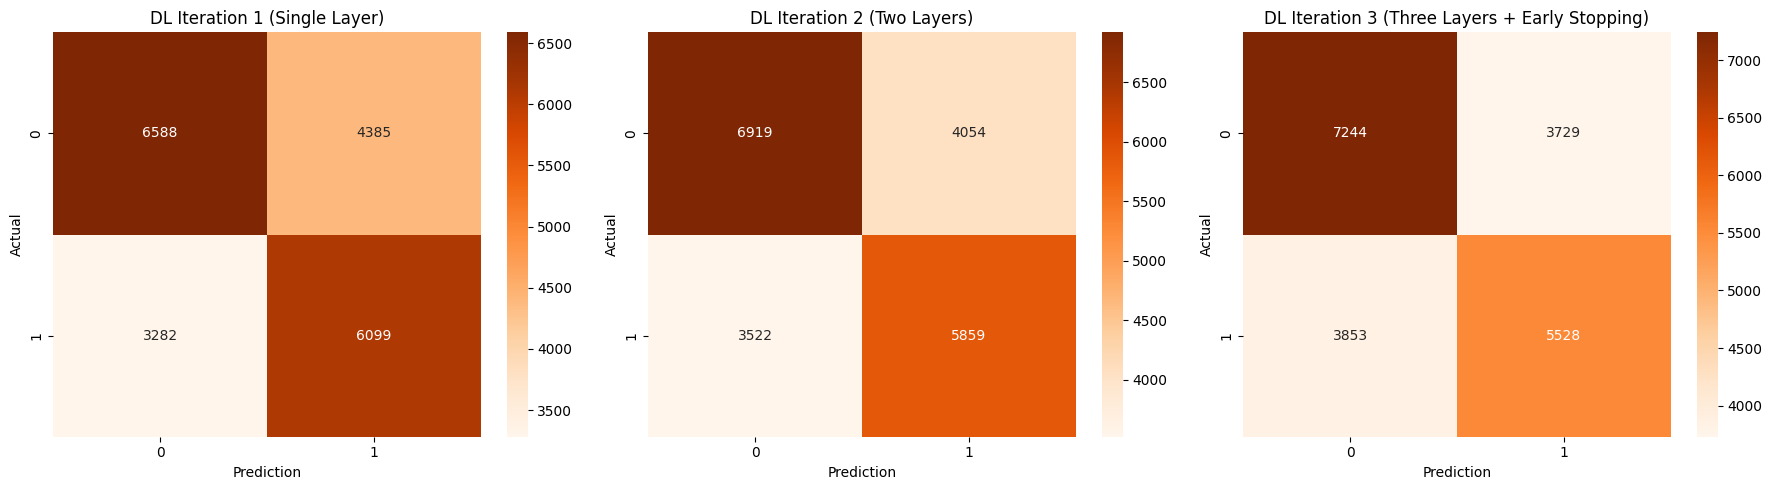

In [3]:
print("STEP 3: DEEP LEARNING RESULTS AND VISUALIZATION ---")

# Printing the Table
dl_df = pd.DataFrame(dl_results)
print("\nDEEP LEARNING COMPARISON TABLE ---")
print(dl_df.to_string(index=False))

# Plotting Confusion Matrices
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for i, (name, cm) in enumerate(dl_cms.items()):
    sns.heatmap(cm, annot=True, fmt='d', cmap='Oranges', ax=axes[i])
    axes[i].set_title(name)
    axes[i].set_xlabel('Prediction')
    axes[i].set_ylabel('Actual')
plt.tight_layout()
plt.show()